# Kushagra Singh 2401PH07

# Q1

In [1]:
x = [-0.86114, -0.33998, 0.33998, 0.86114]
w = [0.34785, 0.65215, 0.65215, 0.34785]

integral = 0
for i in range(4):
    f_x = (8 * (x[i] + 3)) / (16 + (x[i] + 3)**4)
    integral += w[i] * f_x

print("Integeral =",integral)

Integeral = 0.5404100317483954


# Q2

In [2]:
# Changing Variable x=0.5*(t +1)

t = [-0.86114, -0.33998, 0.33998, 0.86114]
w = [0.34785, 0.65215, 0.65215, 0.34785]

integral = 0
for i in range(4):
    x = 0.5 * t[i] + 0.5
    f_x = (1 / (1 + x)) * 0.5
    integral += w[i] * f_x

print(integral)

0.6931463286476849


# Q3

Enter maximum Legendre order:  10


C0 = 3.007019
C1 = -1.131343
C2 = 1.266859
C3 = -0.281452
C4 = -0.690413
C5 = 0.265727
C6 = 0.026967
C7 = 0.028121
C8 = 0.098136
C9 = -0.042239
C10 = -0.000000


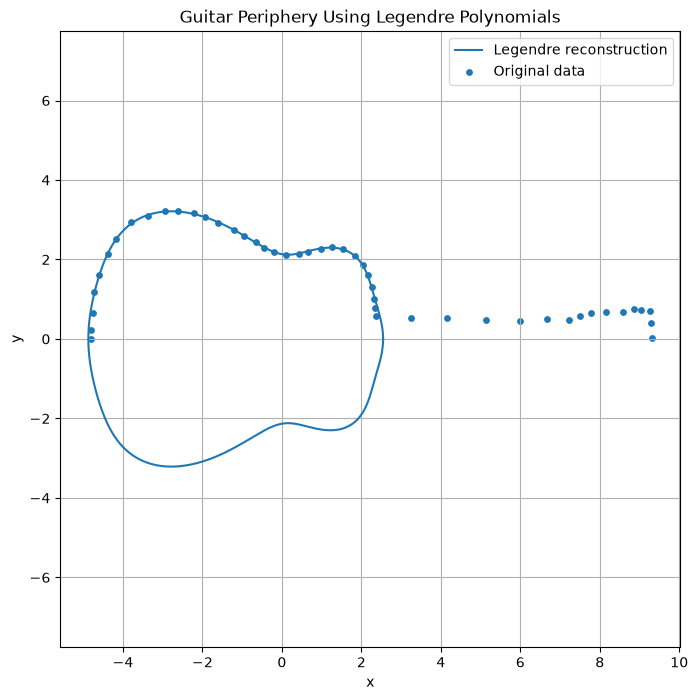

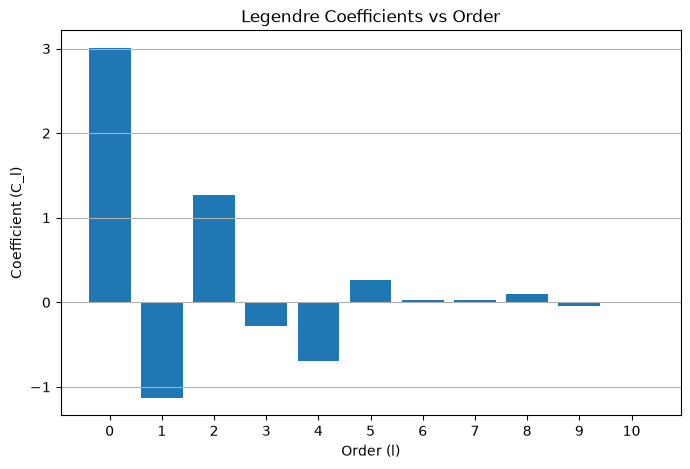

In [11]:
import math
import matplotlib.pyplot as plt

filename = "Guitar_Theta_R.txt"

with open(filename, "r") as f:
    lines = f.readlines()[1:]

theta_data = []
r_data = []

for line in lines:
    values = line.split()
    if len(values) >= 2:
        theta_data.append(float(values[0]))
        r_data.append(float(values[1]))

theta_data = [math.radians(t) for t in theta_data]

nodes = [
    -0.9739065285, -0.8650633666, -0.6794095682,
    -0.4333953941, -0.1488743389, 0.1488743389,
    0.4333953941, 0.6794095682, 0.8650633666,
    0.9739065285
]

weights = [
    0.0666713443, 0.1494513491, 0.2190863625,
    0.2692667193, 0.2955242247, 0.2955242247,
    0.2692667193, 0.2190863625, 0.1494513491,
    0.0666713443
]

def legendre(l, x):
    if l == 0:
        return 1.0
    if l == 1:
        return x

    p0 = 1.0
    p1 = x

    for n in range(2, l + 1):
        p2 = ((2 * n - 1) * x * p1 - (n - 1) * p0) / n
        p0 = p1
        p1 = p2

    return p1

def interpolate(theta):
    theta %= 2 * math.pi

    for i in range(len(theta_data)):
        if theta_data[i] >= theta:
            if i == 0:
                t1 = theta_data[-1] - 2 * math.pi
                r1 = r_data[-1]
                t2 = theta_data[0]
                r2 = r_data[0]
            else:
                t1 = theta_data[i - 1]
                r1 = r_data[i - 1]
                t2 = theta_data[i]
                r2 = r_data[i]

            if t2 == t1:
                return r1

            return r1 + (r2 - r1) * (theta - t1) / (t2 - t1)

    t1 = theta_data[-1]
    r1 = r_data[-1]
    t2 = theta_data[0] + 2 * math.pi
    r2 = r_data[0]

    return r1 + (r2 - r1) * (theta - t1) / (t2 - t1)

def coefficient(l):
    total = 0.0

    for x, w in zip(nodes, weights):
        theta = math.acos(x)
        r = interpolate(theta)
        total += w * r * legendre(l, x)

    return (2 * l + 1) * total / 2

order = int(input("Enter maximum Legendre order: "))

coefficients = []

for l in range(order + 1):
    c = coefficient(l)
    coefficients.append(c)
    print(f"C{l} = {c:.6f}")

def radius(theta):
    x = math.cos(theta)
    total = 0.0

    for l, c in enumerate(coefficients):
        total += c * legendre(l, x)

    return total

theta_plot = [
    2 * math.pi * i / 999 for i in range(1000)
]

r_plot = [radius(t) for t in theta_plot]

x_plot = [r * math.cos(t) for r, t in zip(r_plot, theta_plot)]
y_plot = [r * math.sin(t) for r, t in zip(r_plot, theta_plot)]

x_data = [r * math.cos(t) for r, t in zip(r_data, theta_data)]
y_data = [r * math.sin(t) for r, t in zip(r_data, theta_data)]

plt.figure(figsize=(8, 8))
plt.plot(x_plot, y_plot, label="Legendre reconstruction")
plt.scatter(x_data, y_data, label="Original data", s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Guitar Periphery Using Legendre Polynomials")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()
l_values = list(range(len(coefficients)))

plt.figure(figsize=(8, 5))
plt.bar(l_values, coefficients)
plt.xlabel("Order (l)")
plt.ylabel("Coefficient (C_l)")
plt.title("Legendre Coefficients vs Order")
plt.xticks(l_values)
plt.grid(axis="y")
plt.show()

## Using Cl=30

Enter maximum Legendre order:  30


C0 = 3.02520650
C1 = -1.07322596
C2 = 1.36351293
C3 = -0.14403580
C4 = -0.53813332
C5 = 0.45655609
C6 = 0.25226937
C7 = 0.29847812
C8 = 0.38411076
C9 = 0.27208648
C10 = 0.30407613
C11 = 0.35092389
C12 = 0.34837936
C13 = 0.34247228
C14 = 0.33786991
C15 = 0.32324380
C16 = 0.28652589
C17 = 0.33723821
C18 = 0.29362788
C19 = 0.26425933
C20 = 0.26628160
C21 = 0.21447776
C22 = 0.21260603
C23 = 0.19749175
C24 = 0.17885056
C25 = 0.16602432
C26 = 0.14710327
C27 = 0.14366071
C28 = 0.13625503
C29 = 0.09717293
C30 = 0.10499160


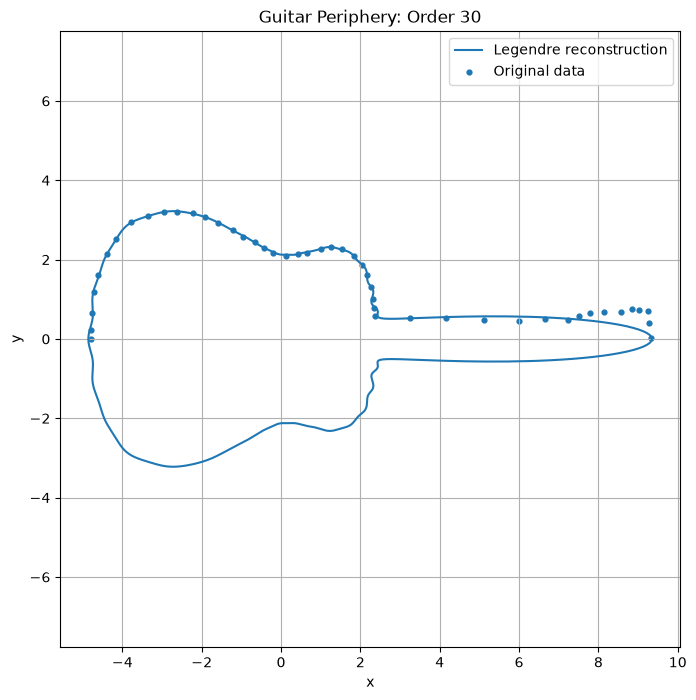

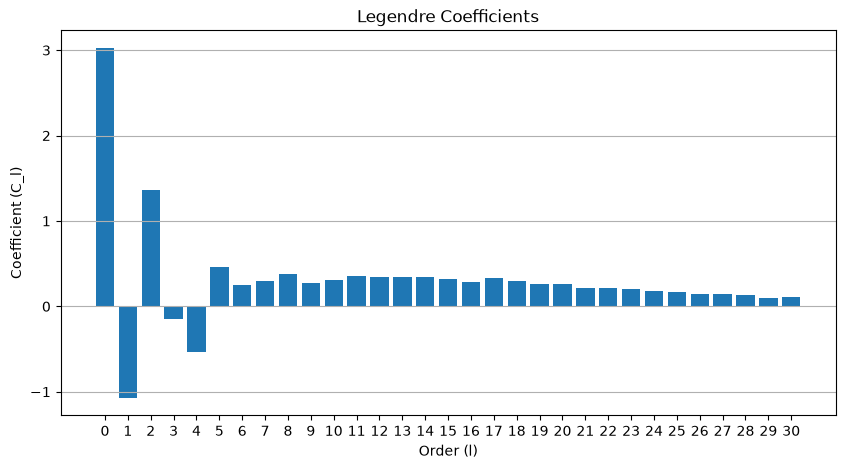

In [12]:

import math
import matplotlib.pyplot as plt
from bisect import bisect_left

filename = "Guitar_Theta_R.txt"

with open(filename, "r") as f:
    lines = f.readlines()[1:]

data = []

for line in lines:
    values = line.split()
    if len(values) >= 2:
        data.append((math.radians(float(values[0])) % (2 * math.pi),
                     float(values[1])))

data.sort()

theta_data = [p[0] for p in data]
r_data = [p[1] for p in data]

if len(theta_data) < 2:
    raise ValueError("At least two data points are required.")

def interpolate(theta):
    theta %= 2 * math.pi
    i = bisect_left(theta_data, theta)

    if i < len(theta_data) and abs(theta_data[i] - theta) < 1e-12:
        return r_data[i]

    if i == 0:
        t1 = theta_data[-1] - 2 * math.pi
        r1 = r_data[-1]
        t2 = theta_data[0]
        r2 = r_data[0]
        if theta < t2:
            theta += 2 * math.pi
    elif i == len(theta_data):
        t1 = theta_data[-1]
        r1 = r_data[-1]
        t2 = theta_data[0] + 2 * math.pi
        r2 = r_data[0]
    else:
        t1, r1 = theta_data[i - 1], r_data[i - 1]
        t2, r2 = theta_data[i], r_data[i]

    if abs(t2 - t1) < 1e-14:
        return r1

    return r1 + (r2 - r1) * (theta - t1) / (t2 - t1)

def legendre(n, x):
    if n == 0:
        return 1.0
    if n == 1:
        return x

    p0, p1 = 1.0, x

    for k in range(2, n + 1):
        p0, p1 = p1, ((2 * k - 1) * x * p1 - (k - 1) * p0) / k

    return p1

def gauss_legendre(n):
    nodes = []
    weights = []

    for i in range(1, n + 1):
        x = math.cos(math.pi * (i - 0.25) / (n + 0.5))

        for _ in range(100):
            p = legendre(n, x)
            dp = n * (x * p - legendre(n - 1, x)) / (x * x - 1)
            dx = p / dp
            x -= dx

            if abs(dx) < 1e-14:
                break

        p = legendre(n, x)
        dp = n * (x * p - legendre(n - 1, x)) / (x * x - 1)
        w = 2 / ((1 - x * x) * dp * dp)

        nodes.append(x)
        weights.append(w)

    pairs = sorted(zip(nodes, weights))
    return [p[0] for p in pairs], [p[1] for p in pairs]

order = int(input("Enter maximum Legendre order: "))

if order < 0:
    raise ValueError("Order must be non-negative.")

quadrature_count = max(200, 4 * (order + 1))
nodes, weights = gauss_legendre(quadrature_count)

coefficients = []

for l in range(order + 1):
    total = 0.0

    for x, w in zip(nodes, weights):
        theta = math.acos(x)
        r = interpolate(theta)
        total += w * r * legendre(l, x)

    c = (2 * l + 1) * total / 2
    coefficients.append(c)
    print(f"C{l} = {c:.8f}")

def radius(theta):
    x = math.cos(theta)
    total = 0.0

    for l, c in enumerate(coefficients):
        total += c * legendre(l, x)

    return total

count = 1200
theta_plot = [2 * math.pi * i / count for i in range(count + 1)]
r_plot = [radius(t) for t in theta_plot]

x_plot = [r * math.cos(t) for r, t in zip(r_plot, theta_plot)]
y_plot = [r * math.sin(t) for r, t in zip(r_plot, theta_plot)]

x_data = [r * math.cos(t) for r, t in zip(r_data, theta_data)]
y_data = [r * math.sin(t) for r, t in zip(r_data, theta_data)]

plt.figure(figsize=(8, 8))
plt.plot(x_plot, y_plot, label="Legendre reconstruction")
plt.scatter(x_data, y_data, s=12, label="Original data")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Guitar Periphery: Order {order}")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

l_values = list(range(len(coefficients)))

plt.figure(figsize=(10, 5))
plt.bar(l_values, coefficients)
plt.xlabel("Order (l)")
plt.ylabel("Coefficient (C_l)")
plt.title("Legendre Coefficients")
plt.xticks(l_values)
plt.grid(axis="y")
plt.show()


# Using Cl=47  to approximating Exact Curve

Enter maximum Legendre order:  47


C0 = 3.02520650
C1 = -1.07322596
C2 = 1.36351293
C3 = -0.14403580
C4 = -0.53813332
C5 = 0.45655609
C6 = 0.25226937
C7 = 0.29847812
C8 = 0.38411076
C9 = 0.27208648
C10 = 0.30407613
C11 = 0.35092389
C12 = 0.34837936
C13 = 0.34247228
C14 = 0.33786991
C15 = 0.32324380
C16 = 0.28652589
C17 = 0.33723821
C18 = 0.29362788
C19 = 0.26425933
C20 = 0.26628160
C21 = 0.21447776
C22 = 0.21260603
C23 = 0.19749175
C24 = 0.17885056
C25 = 0.16602432
C26 = 0.14710327
C27 = 0.14366071
C28 = 0.13625503
C29 = 0.09717293
C30 = 0.10499160
C31 = 0.10734598
C32 = 0.09727940
C33 = 0.07302485
C34 = 0.07625531
C35 = 0.08579186
C36 = 0.04990434
C37 = 0.05656495
C38 = 0.06509088
C39 = 0.02499115
C40 = 0.04451744
C41 = 0.04382212
C42 = 0.00320541
C43 = 0.02621684
C44 = 0.01820262
C45 = -0.00286002
C46 = -0.00811402
C47 = -0.00545053


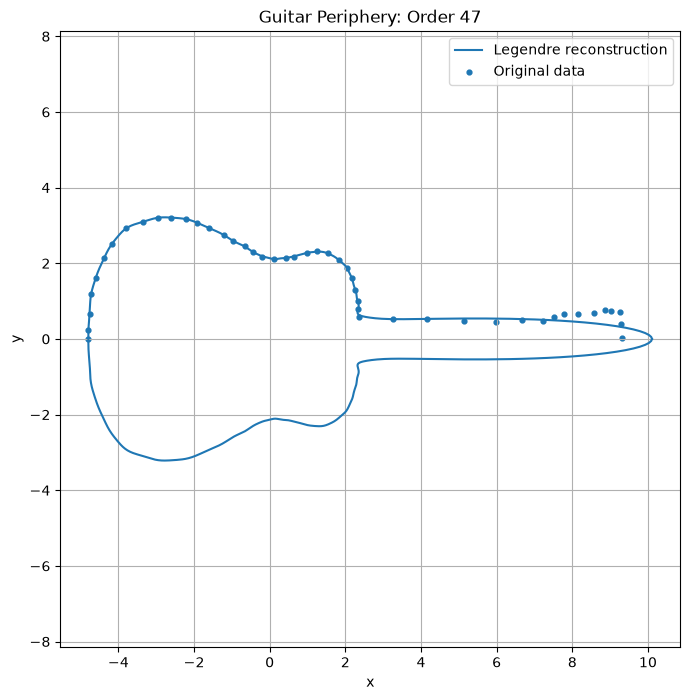

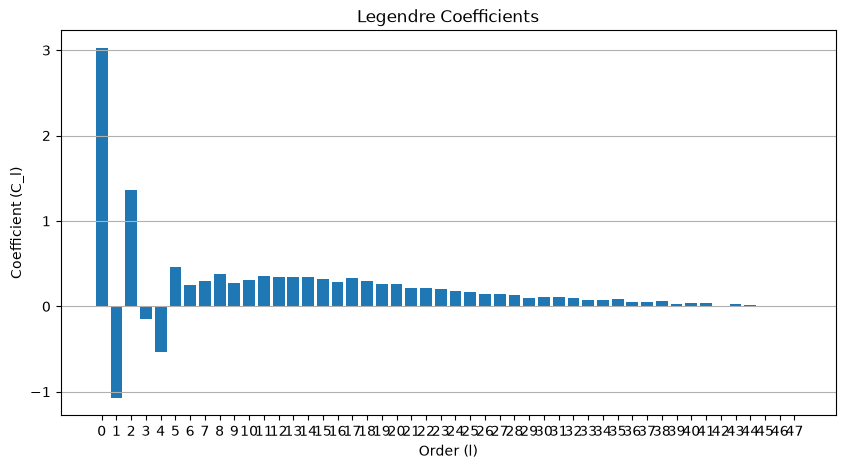

In [13]:

import math
import matplotlib.pyplot as plt
from bisect import bisect_left

filename = "Guitar_Theta_R.txt"

with open(filename, "r") as f:
    lines = f.readlines()[1:]

data = []

for line in lines:
    values = line.split()
    if len(values) >= 2:
        data.append((math.radians(float(values[0])) % (2 * math.pi),
                     float(values[1])))

data.sort()

theta_data = [p[0] for p in data]
r_data = [p[1] for p in data]

if len(theta_data) < 2:
    raise ValueError("At least two data points are required.")

def interpolate(theta):
    theta %= 2 * math.pi
    i = bisect_left(theta_data, theta)

    if i < len(theta_data) and abs(theta_data[i] - theta) < 1e-12:
        return r_data[i]

    if i == 0:
        t1 = theta_data[-1] - 2 * math.pi
        r1 = r_data[-1]
        t2 = theta_data[0]
        r2 = r_data[0]
        if theta < t2:
            theta += 2 * math.pi
    elif i == len(theta_data):
        t1 = theta_data[-1]
        r1 = r_data[-1]
        t2 = theta_data[0] + 2 * math.pi
        r2 = r_data[0]
    else:
        t1, r1 = theta_data[i - 1], r_data[i - 1]
        t2, r2 = theta_data[i], r_data[i]

    if abs(t2 - t1) < 1e-14:
        return r1

    return r1 + (r2 - r1) * (theta - t1) / (t2 - t1)

def legendre(n, x):
    if n == 0:
        return 1.0
    if n == 1:
        return x

    p0, p1 = 1.0, x

    for k in range(2, n + 1):
        p0, p1 = p1, ((2 * k - 1) * x * p1 - (k - 1) * p0) / k

    return p1

def gauss_legendre(n):
    nodes = []
    weights = []

    for i in range(1, n + 1):
        x = math.cos(math.pi * (i - 0.25) / (n + 0.5))

        for _ in range(100):
            p = legendre(n, x)
            dp = n * (x * p - legendre(n - 1, x)) / (x * x - 1)
            dx = p / dp
            x -= dx

            if abs(dx) < 1e-14:
                break

        p = legendre(n, x)
        dp = n * (x * p - legendre(n - 1, x)) / (x * x - 1)
        w = 2 / ((1 - x * x) * dp * dp)

        nodes.append(x)
        weights.append(w)

    pairs = sorted(zip(nodes, weights))
    return [p[0] for p in pairs], [p[1] for p in pairs]

order = int(input("Enter maximum Legendre order: "))

if order < 0:
    raise ValueError("Order must be non-negative.")

quadrature_count = max(200, 4 * (order + 1))
nodes, weights = gauss_legendre(quadrature_count)

coefficients = []

for l in range(order + 1):
    total = 0.0

    for x, w in zip(nodes, weights):
        theta = math.acos(x)
        r = interpolate(theta)
        total += w * r * legendre(l, x)

    c = (2 * l + 1) * total / 2
    coefficients.append(c)
    print(f"C{l} = {c:.8f}")

def radius(theta):
    x = math.cos(theta)
    total = 0.0

    for l, c in enumerate(coefficients):
        total += c * legendre(l, x)

    return total

count = 1200
theta_plot = [2 * math.pi * i / count for i in range(count + 1)]
r_plot = [radius(t) for t in theta_plot]

x_plot = [r * math.cos(t) for r, t in zip(r_plot, theta_plot)]
y_plot = [r * math.sin(t) for r, t in zip(r_plot, theta_plot)]

x_data = [r * math.cos(t) for r, t in zip(r_data, theta_data)]
y_data = [r * math.sin(t) for r, t in zip(r_data, theta_data)]

plt.figure(figsize=(8, 8))
plt.plot(x_plot, y_plot, label="Legendre reconstruction")
plt.scatter(x_data, y_data, s=12, label="Original data")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Guitar Periphery: Order {order}")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

l_values = list(range(len(coefficients)))

plt.figure(figsize=(10, 5))
plt.bar(l_values, coefficients)
plt.xlabel("Order (l)")
plt.ylabel("Coefficient (C_l)")
plt.title("Legendre Coefficients")
plt.xticks(l_values)
plt.grid(axis="y")
plt.show()


## Making Full Body

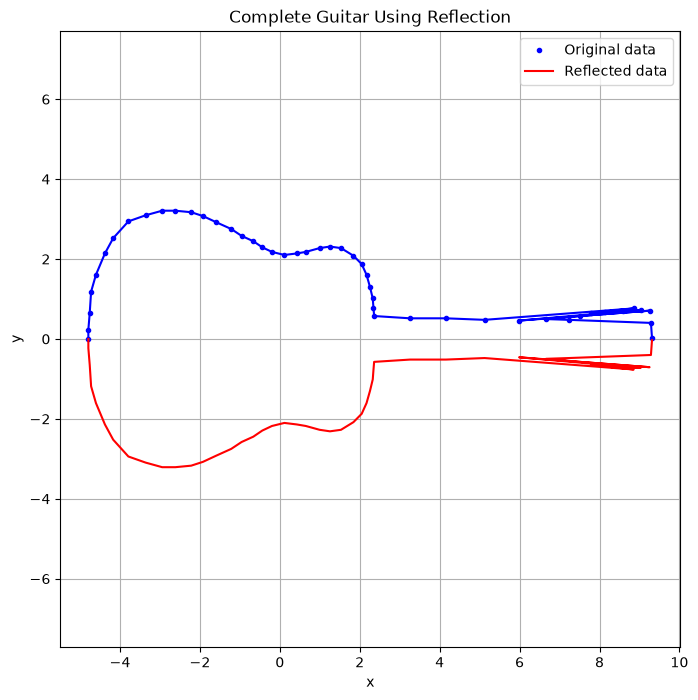

In [ ]:
import math
import matplotlib.pyplot as plt
from bisect import bisect_left

filename = "Guitar_Theta_R.txt"

with open(filename, "r") as f:
    lines = f.readlines()[1:]

data = []

for line in lines:
    values = line.split()
    if len(values) >= 2:
        data.append((math.radians(float(values[0])), float(values[1])))

data.sort()

theta_data = [p[0] for p in data]
r_data = [p[1] for p in data]

x_original = [r * math.cos(t) for t, r in zip(theta_data, r_data)]
y_original = [r * math.sin(t) for t, r in zip(theta_data, r_data)]

x_full = x_original + x_original[::-1]
y_full = y_original + [-y for y in y_original[::-1]]

plt.figure(figsize=(8, 8))
plt.plot(x_original, y_original, 'b.', label="Original data")
plt.plot(x_original, y_original, 'b-')
plt.plot(x_original[::-1], [-y for y in y_original[::-1]], 'r-', label="Reflected data")
plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Complete Guitar Using Reflection")
plt.grid(True)
plt.legend()
plt.show()

def interpolate(theta):
    theta %= 2 * math.pi
    i = bisect_left(theta_data, theta)

    if i == 0:
        t1, r1 = theta_data[-1] - 2 * math.pi, r_data[-1]
        t2, r2 = theta_data[0], r_data[0]
        if theta < t2:
            theta += 2 * math.pi
    elif i == len(theta_data):
        t1, r1 = theta_data[-1], r_data[-1]
        t2, r2 = theta_data[0] + 2 * math.pi, r_data[0]
    else:
        t1, r1 = theta_data[i - 1], r_data[i - 1]
        t2, r2 = theta_data[i], r_data[i]

    if abs(t2 - t1) < 1e-14:
        return r1

    return r1 + (r2 - r1) * (theta - t1) / (t2 - t1)

def legendre(n, x):
    if n == 0:
        return 1.0
    if n == 1:
        return x

    p0, p1 = 1.0, x

    for k in range(2, n + 1):
        p0, p1 = p1, ((2 * k - 1) * x * p1 - (k - 1) * p0) / k

    return p1

def gauss_legendre(n):
    nodes, weights = [], []

    for i in range(1, n + 1):
        x = math.cos(math.pi * (i - 0.25) / (n + 0.5))

        for _ in range(100):
            p = legendre(n, x)
            dp = n * (x * p - legendre(n - 1, x)) / (x * x - 1)
            dx = p / dp
            x -= dx

            if abs(dx) < 1e-14:
                break

        p = legendre(n, x)
        dp = n * (x * p - legendre(n - 1, x)) / (x * x - 1)
        nodes.append(x)
        weights.append(2 / ((1 - x * x) * dp * dp))

    pairs = sorted(zip(nodes, weights))
    return [p[0] for p in pairs], [p[1] for p in pairs]

order = int(input("Enter maximum Legendre order: "))

nodes, weights = gauss_legendre(max(200, 4 * (order + 1)))

coefficients = []

for l in range(order + 1):
    total = 0.0

    for x, w in zip(nodes, weights):
        total += w * interpolate(math.acos(x)) * legendre(l, x)

    c = (2 * l + 1) * total / 2
    coefficients.append(c)
    print(f"C{l} = {c:.8f}")

def radius(theta):
    x = math.cos(theta)
    return sum(c * legendre(l, x) for l, c in enumerate(coefficients))

theta_plot = [2 * math.pi * i / 1600 for i in range(1601)]
r_plot = [radius(t) for t in theta_plot]

x_plot = [r * math.cos(t) for r, t in zip(r_plot, theta_plot)]
y_plot = [r * math.sin(t) for r, t in zip(r_plot, theta_plot)]

plt.figure(figsize=(8, 8))
plt.plot(x_plot, y_plot, label="Legendre reconstruction")
plt.plot(x_full, y_full, 'r.', markersize=2, label="Reflected original data")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Complete Guitar: Legendre Order {order}")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(range(len(coefficients)), coefficients)
plt.xlabel("Order (l)")
plt.ylabel("Coefficient (C_l)")
plt.title("Legendre Coefficients")
plt.xticks(range(len(coefficients)))
plt.grid(axis="y")
plt.show()